In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [8]:
df=pd.read_csv("../data/data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [9]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [11]:
df.shape

(569, 33)

In [12]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='str')

Last col is empty. No need for it at all. And id column doesn't help with output prediction.

In [13]:
df=df.drop(columns="Unnamed: 32")

In [14]:
df=df.drop(columns="id")

In [15]:
df.shape

(569, 31)

No other column has any missing values.

In [16]:
df.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

Now check for duplicates.

In [17]:
df.duplicated().sum()

np.int64(0)

No duplicates as well. We move on to univariate analysis.

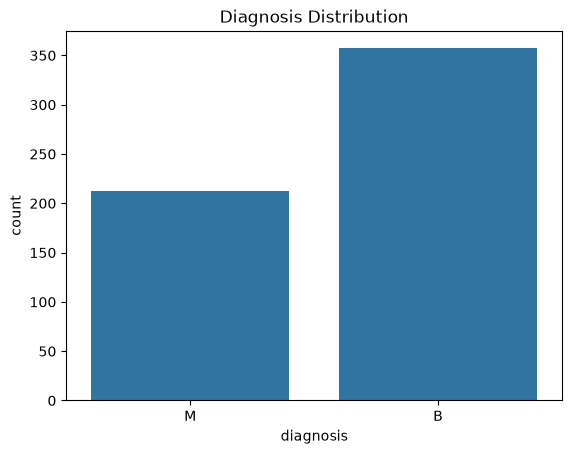

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="diagnosis", data=df)
plt.title("Diagnosis Distribution")
plt.show()

We observe unbalanced data. So we will stratify the Y column for training data later

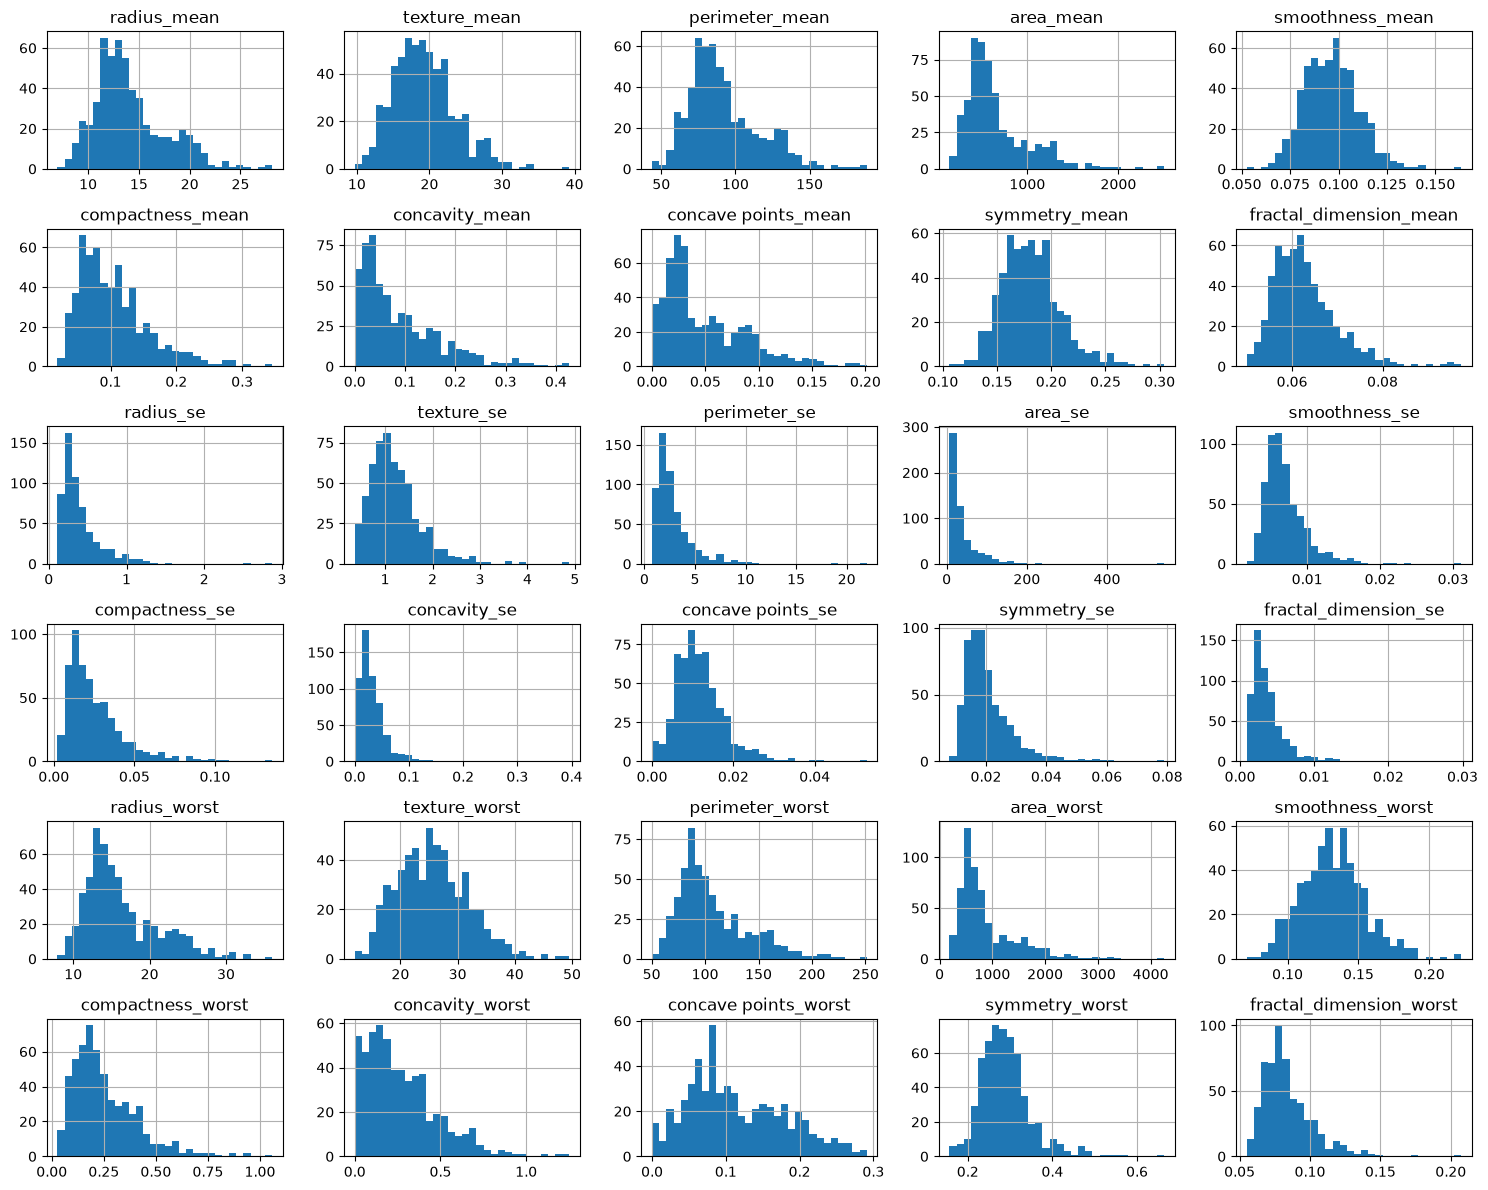

In [19]:
df.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

Several features especially the _se and area-related features have right skewness with long right tails. More values are low than high. Only few datapoints have high values.


smoothness_mean,texture_mean,symmetry_mean,smoothness_worse have the most approx. normal curves. roughly unimodal.

radius_mean, perimeter_mean, radius_worst, perimeter_worst, area_worst, concave_points_worst, texture_worst have multiple peaks. multimodal. Maybe coz of the 2 classes: Benign and malign being different distributions.

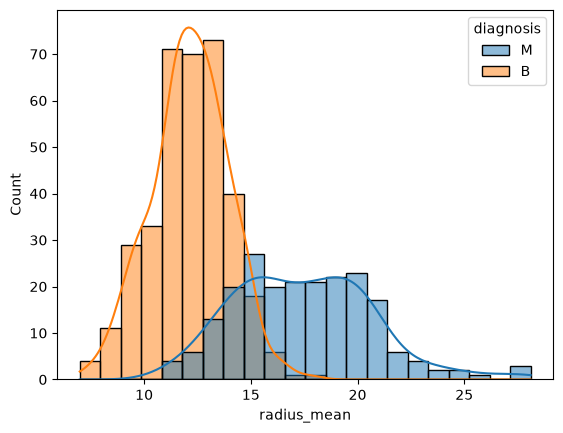

In [20]:
sns.histplot(data=df, x="radius_mean", hue="diagnosis", kde=True)
plt.show()

We observe B is more normal, less variance curve. M has a bell shaped too. but slightly dipped on top. It has more variance.

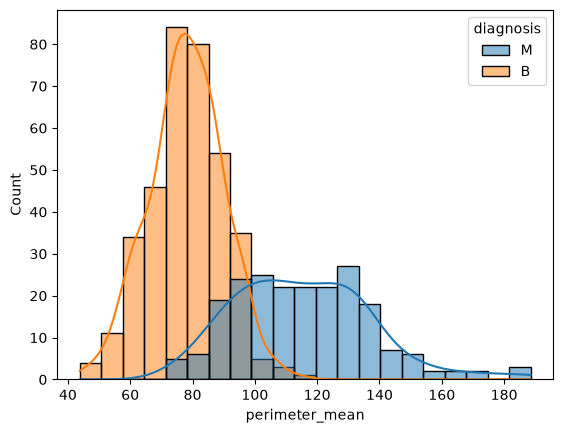

In [21]:
sns.histplot(data=df, x="perimeter_mean", hue="diagnosis", kde=True)
plt.show()

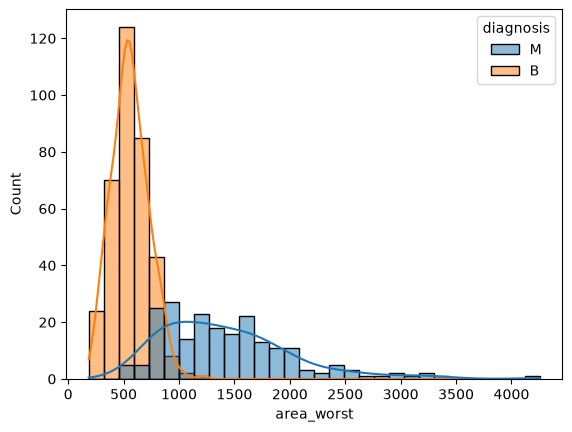

In [22]:
sns.histplot(data=df, x="area_worst", hue="diagnosis", kde=True)
plt.show()

We observe that the multi peaks in the histograms are mostly due to the classes distributions being different. We observe that benign tumors have lower values compared to malign.

area_mean
area_se
radius_se
perimeter_se
area_worst
fractal_dimension_se
have some obvious extreme values. So check for outliers.

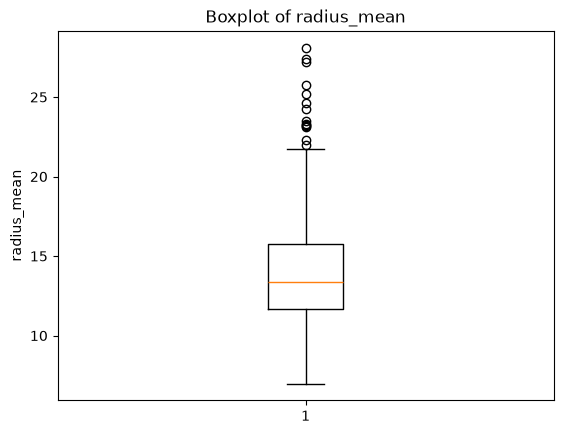

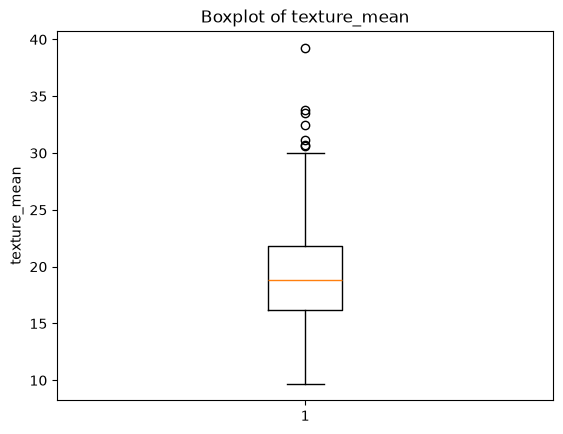

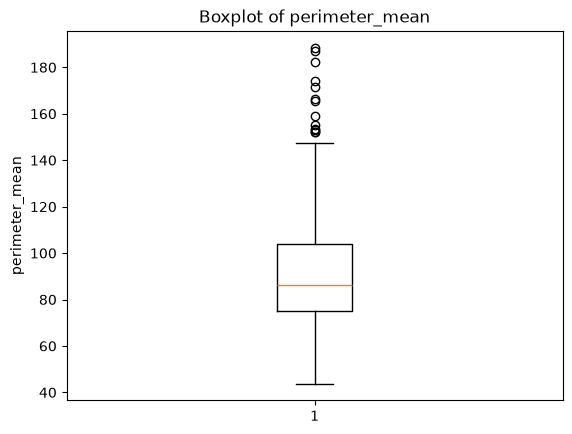

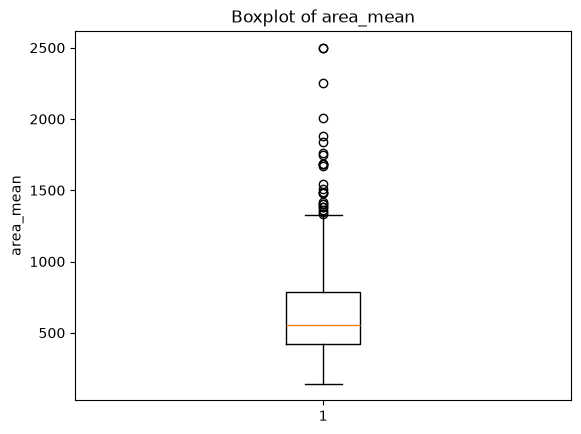

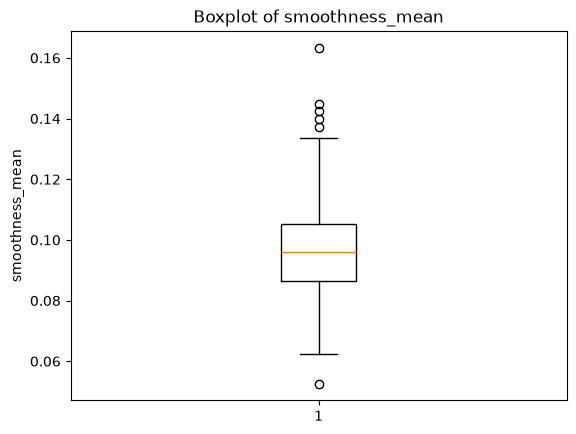

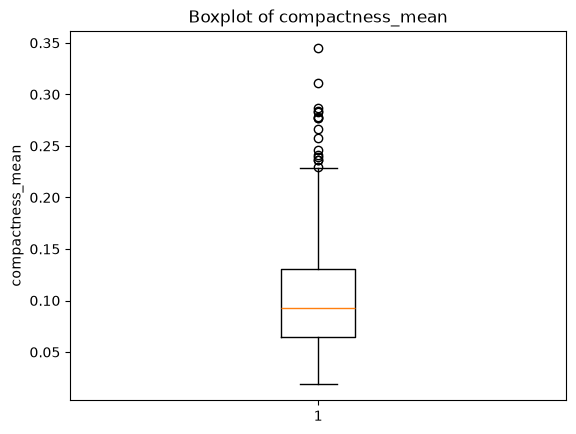

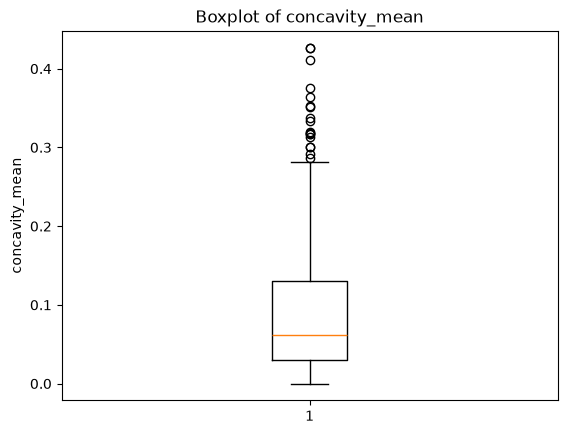

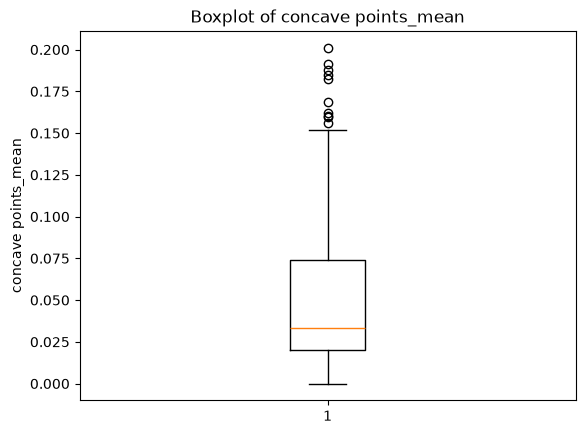

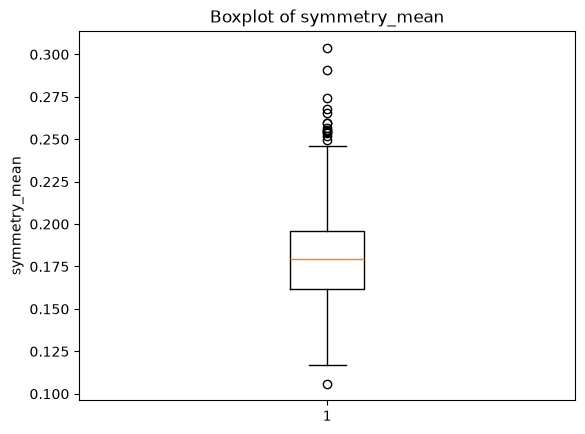

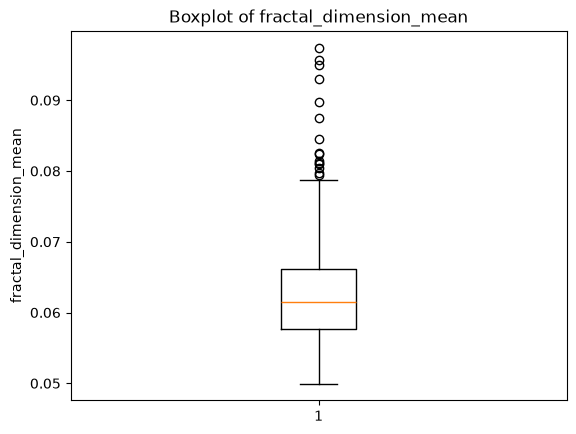

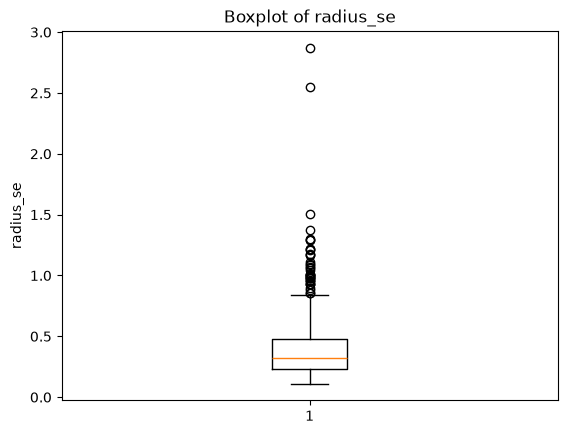

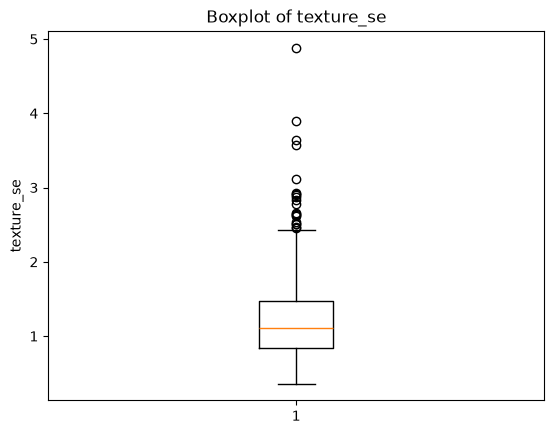

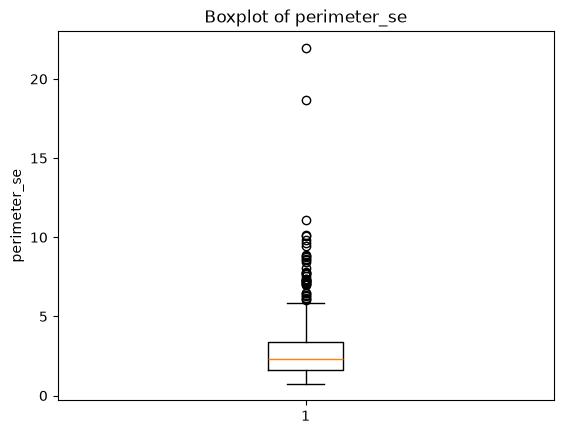

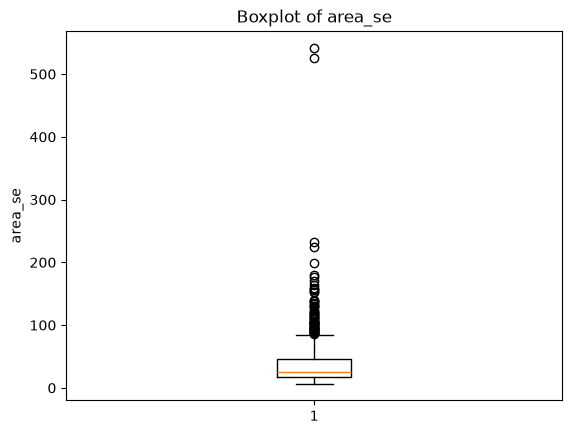

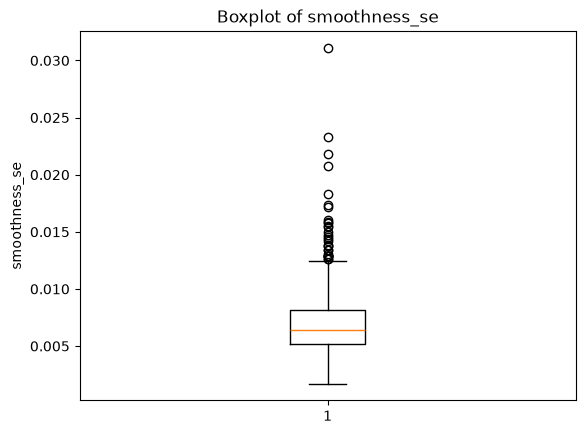

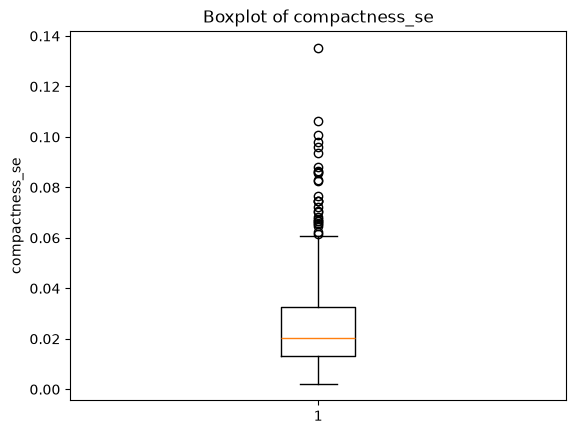

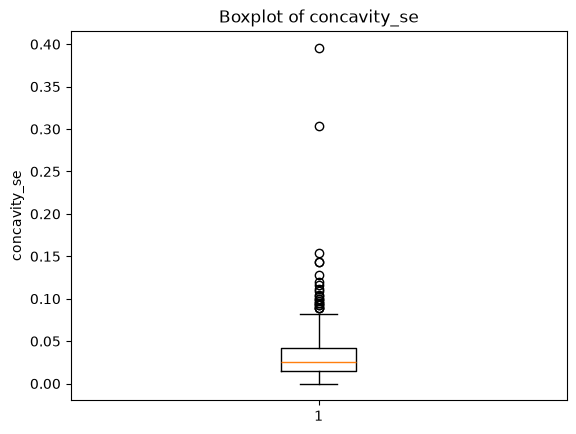

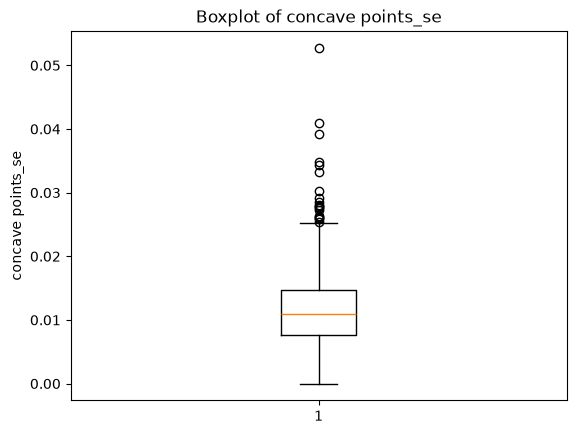

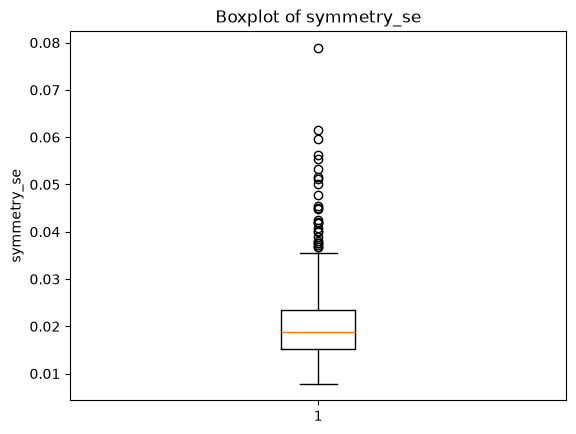

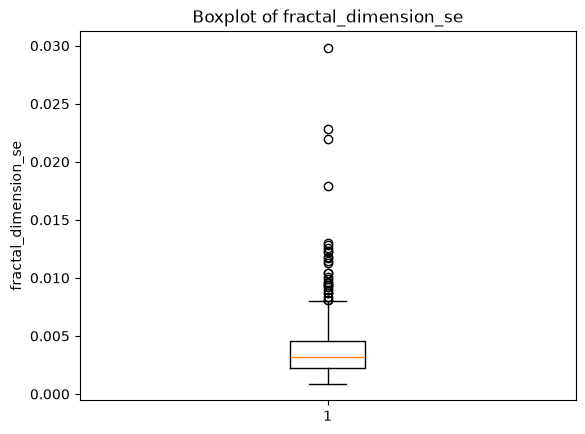

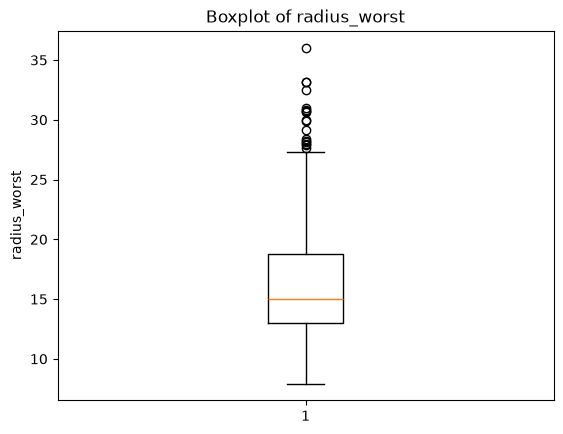

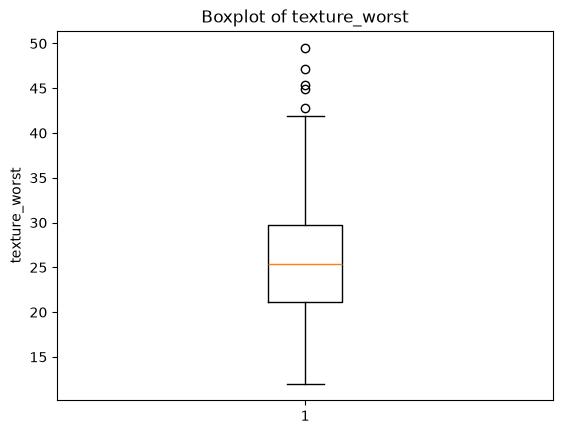

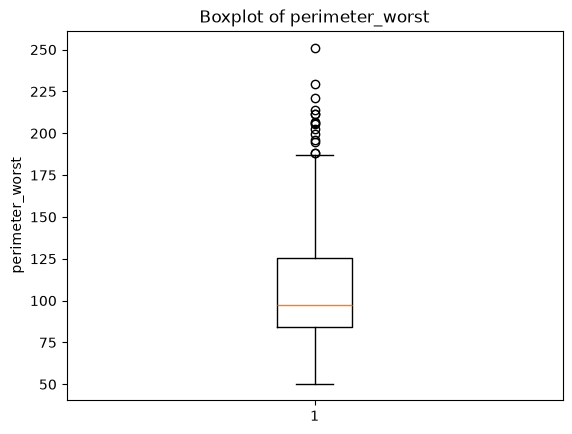

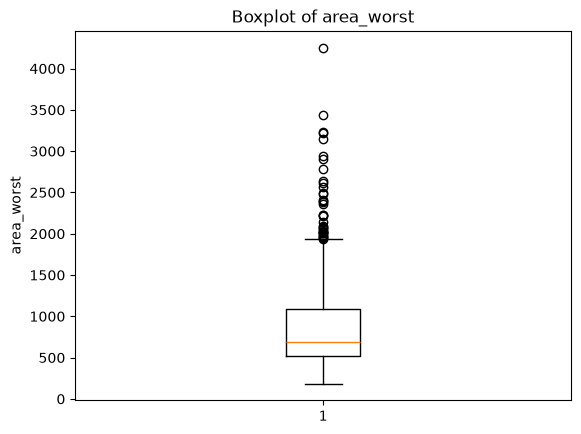

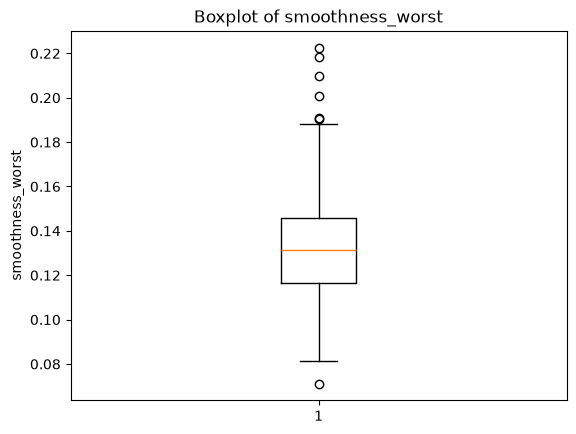

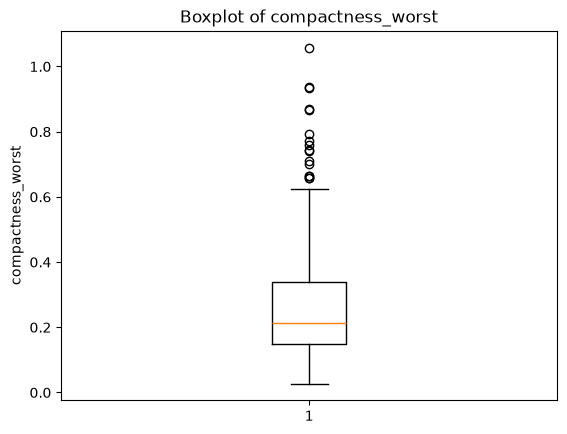

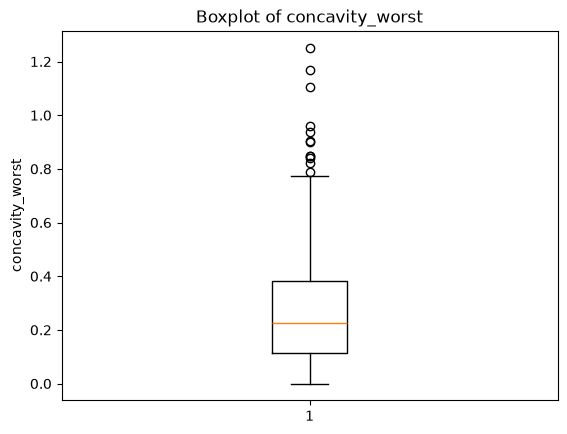

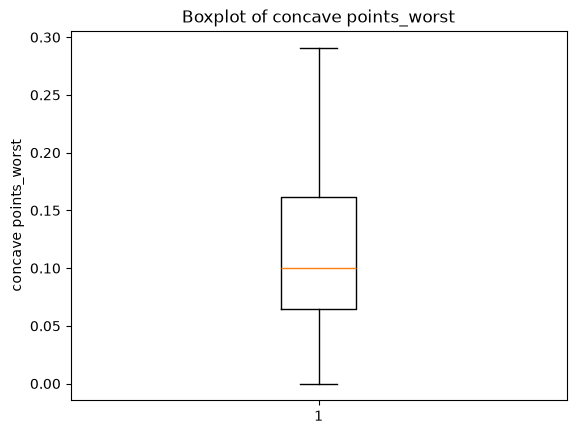

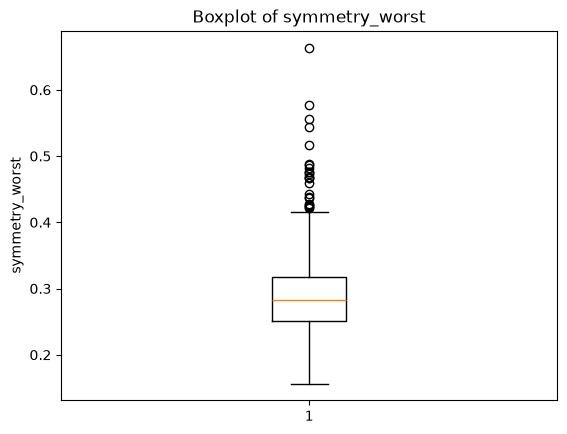

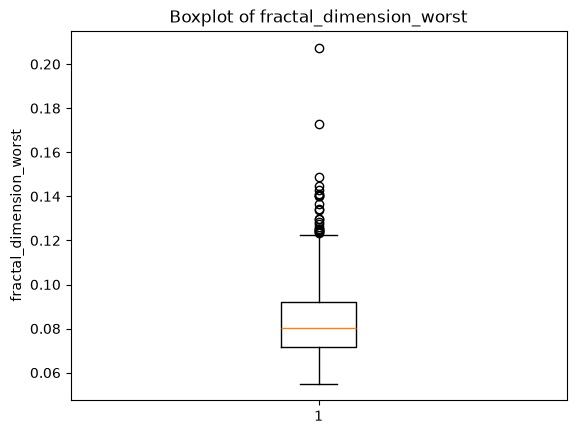

In [23]:
cols = df.columns

for i in range(1, 31):
    plt.boxplot(df[cols[i]])
    plt.title("Boxplot of " + cols[i])
    plt.ylabel(cols[i])
    plt.show()

Almost all of _se have very far outliers. _worst has far outliers too, but they are not many(except area_worst and fractal_worst, symmetry worst)
concave_points_worst has no outliers. _mean have few outliers not very far, except area_mean and 2 others.

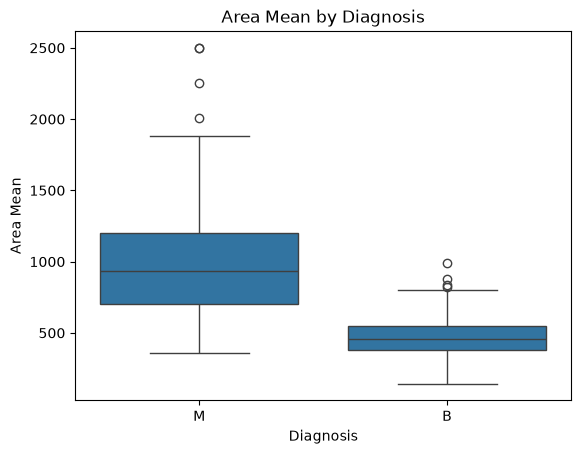

In [24]:
sns.boxplot(x="diagnosis", y="area_mean", data=df)

plt.title("Area Mean by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Area Mean")
plt.show()

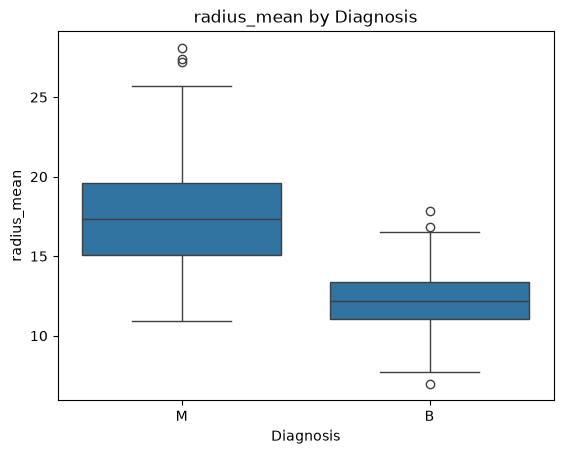

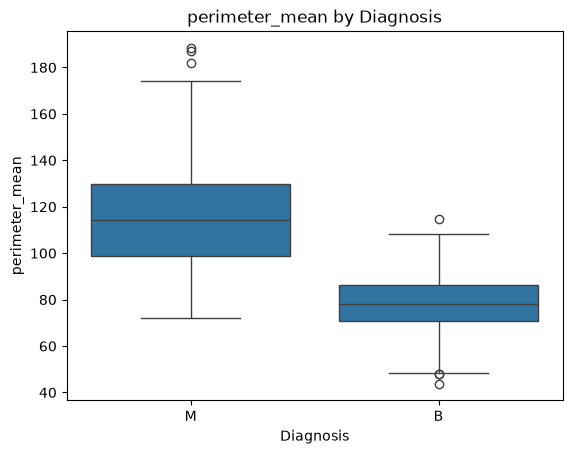

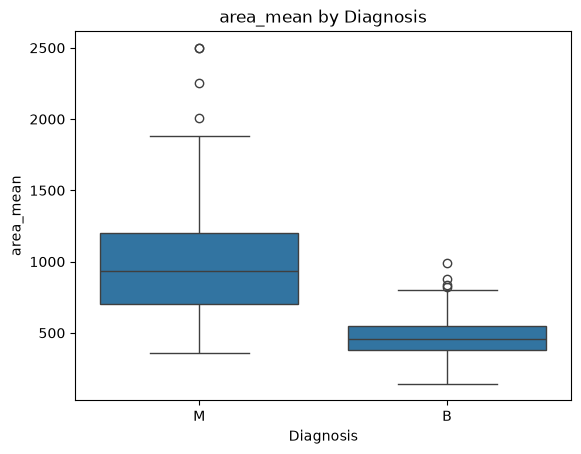

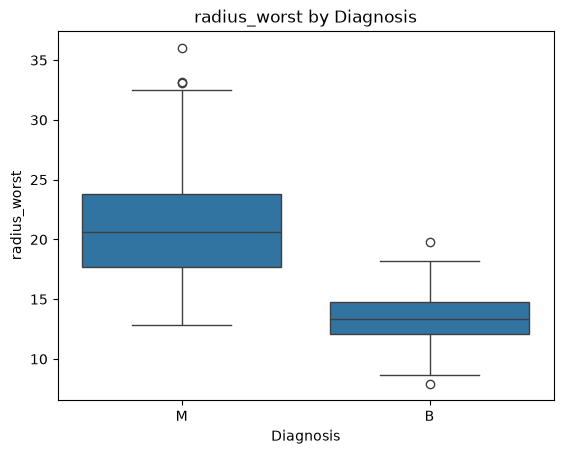

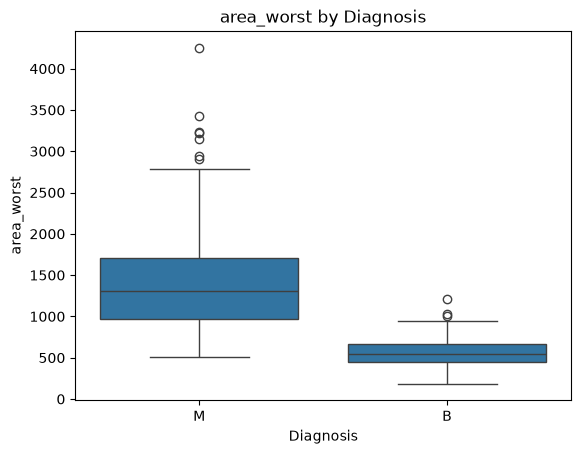

In [25]:
features = ["radius_mean", "perimeter_mean", "area_mean",
            "radius_worst", "area_worst"]

for col in features:
    sns.boxplot(x="diagnosis", y=col, data=df)
    plt.title(f"{col} by Diagnosis")
    plt.xlabel("Diagnosis")
    plt.ylabel(col)
    plt.show()

We observe M always stays at the higher end of values. There is little overlap in the both class values. Strong Class Separation.
 The no. of outliers in separate and combined plot has obviously decreased. suggesting that some observations identified as outliers in the combined distribution were actually extreme values relative to the other class rather than unusual observations within their own class.

In [26]:
corr=df.drop(columns="diagnosis").corr()

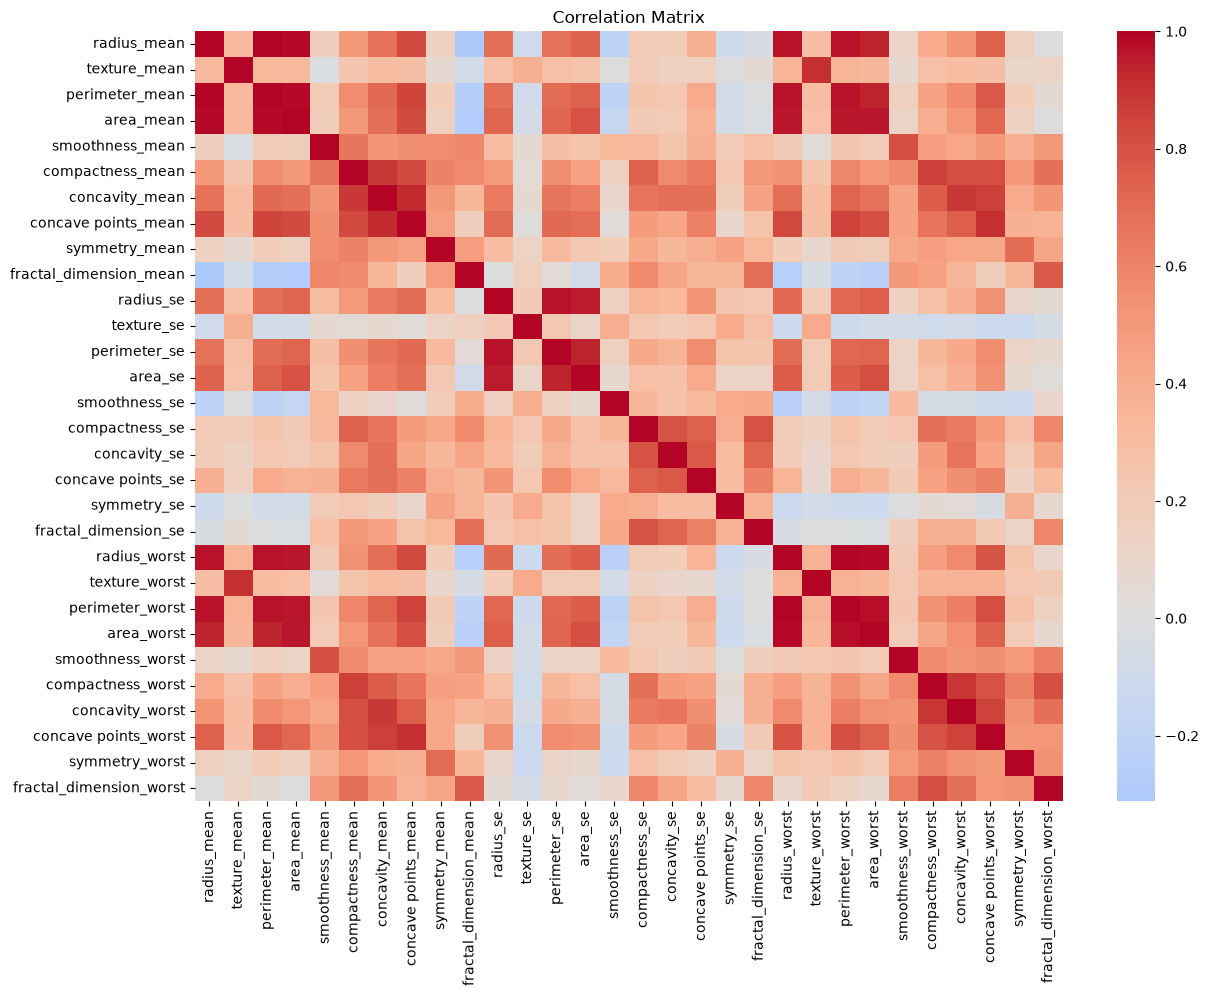

In [27]:
plt.figure(figsize=(14, 10))

sns.heatmap(corr, cmap="coolwarm", center=0)

plt.title("Correlation Matrix")
plt.show()

High correlations between:
radius_mean and perimeter_mean,area_mean,radius_worst,perimeter_worst,area_worst,smoothness_worst
texture_mean with texture_worst
smoothness_mean with smoothness_worst
compactness_mean with concavity_mean,concave points_mean, same _worst
radius_Se with perimeter_Se, area_Se

Now, that we have analyzed our data, we will start to choose a model. This is a classification problem. The target column 'diagnosis' is categorical. SO first we transform it into numerical values. We choose M-1,B-0 coz M is more important output.

In [28]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [29]:
df['diagnosis']=df['diagnosis'].map({"B":0,"M":1})
df['diagnosis']

0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int64

Now all our columns are numerical. We separate features and target then do train test split.

In [30]:
X=df.drop(columns='diagnosis')
Y=df['diagnosis']

In [31]:
X.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [32]:
Y.head()

0    1
1    1
2    1
3    1
4    1
Name: diagnosis, dtype: int64

In [33]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=2,stratify=Y)

In [34]:
X_train.shape

(455, 30)

In [35]:
Y_train.shape

(455,)

In [36]:
sc=StandardScaler()
X_train_sc=sc.fit_transform(X_train,Y_train)
X_test_sc=sc.transform(X_test)

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,recall_score,roc_auc_score,f1_score,precision_score,confusion_matrix,roc_curve

In [38]:
models=[LogisticRegression(),KNeighborsClassifier(),GaussianNB(),RandomForestClassifier(),SVC(),DecisionTreeClassifier()]
def model_accuracy(model):
    model.fit(X_train_sc,Y_train)
    y_pred=model.predict(X_test_sc)
    acc=accuracy_score(y_pred,Y_test)
    print(model," Accuracy= ",acc)
    print("Precision:", precision_score(Y_test, y_pred))
    print("Recall   :", recall_score(Y_test, y_pred))
    print("F1 Score :", f1_score(Y_test, y_pred))
    cf=confusion_matrix(Y_test,y_pred)
    print(cf)


In [39]:
for model in models:
    model_accuracy(model)

LogisticRegression()  Accuracy=  0.9649122807017544
Precision: 0.9523809523809523
Recall   : 0.9523809523809523
F1 Score : 0.9523809523809523
[[70  2]
 [ 2 40]]
KNeighborsClassifier()  Accuracy=  0.956140350877193
Precision: 1.0
Recall   : 0.8809523809523809
F1 Score : 0.9367088607594937
[[72  0]
 [ 5 37]]
GaussianNB()  Accuracy=  0.9122807017543859
Precision: 0.9210526315789473
Recall   : 0.8333333333333334
F1 Score : 0.875
[[69  3]
 [ 7 35]]
RandomForestClassifier()  Accuracy=  0.956140350877193
Precision: 0.9512195121951219
Recall   : 0.9285714285714286
F1 Score : 0.9397590361445783
[[70  2]
 [ 3 39]]
SVC()  Accuracy=  0.9649122807017544
Precision: 0.975
Recall   : 0.9285714285714286
F1 Score : 0.9512195121951219
[[71  1]
 [ 3 39]]
DecisionTreeClassifier()  Accuracy=  0.9298245614035088
Precision: 0.9047619047619048
Recall   : 0.9047619047619048
F1 Score : 0.9047619047619048
[[68  4]
 [ 4 38]]


Precision answers: Of all cases marked as M, how many were actually M?

Recall answers: Of all cases that were actually M, how many were marked as M?

For us, High recall is important more than Precision. So, Logistic Regression is by far the best. followed by SVC then Random Forest

Now cross validation

In [40]:
from sklearn.model_selection import cross_val_score
for model in models:
    f1=cross_val_score(model, X_train_sc,Y_train,cv=5,scoring="f1")
    recall=cross_val_score(model,X_train_sc,Y_train,cv=5,scoring="recall")
    print(model," F1: ",f1.mean()," Recall: ",recall.mean())


LogisticRegression()  F1:  0.9669339111592633  Recall:  0.9588235294117646
KNeighborsClassifier()  F1:  0.9583379768038908  Recall:  0.9470588235294117
GaussianNB()  F1:  0.928410025249358  Recall:  0.9176470588235294
RandomForestClassifier()  F1:  0.9426934340169634  Recall:  0.9235294117647058
SVC()  F1:  0.9613472801708095  Recall:  0.9529411764705882
DecisionTreeClassifier()  F1:  0.8943195611552099  Recall:  0.9176470588235294


Both SVC and Logistic Regression are top 2 right now. And KNN has improved. Kick DEcision Tree, NB. WE will train: LOR,SVC,KNN,RandomForest

In [60]:
from sklearn.model_selection import GridSearchCV
param={
    "max_iter":[100,150,200,500,1000],
    "C":[0.001,0.01,0.1,1,10,100]
}
grid_lr=GridSearchCV(LogisticRegression(),param,scoring="recall",cv=5,n_jobs=-1)
grid_lr.fit(X_train_sc, Y_train)

print(grid_lr.best_params_)
print(grid_lr.best_score_)

{'C': 1, 'max_iter': 100}
0.9588235294117646


In [ ]:
from sklearn.model_selection import GridSearchCV
param={
    "kernel":['linear', 'poly', 'rbf', 'sigmoid'],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "C":[0.001,0.01,0.1,1,10,100]
}
grid=GridSearchCV(SVC(),param,scoring="recall",cv=5,n_jobs=-1)
grid.fit(X_train_sc, Y_train)

print(grid.best_params_)
print(grid.best_score_)

{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
0.9705882352941178


In [ ]:
from sklearn.model_selection import GridSearchCV
param={
    "n_neighbors":[3,5,7,9,11,15,20],
    "weights":['uniform', 'distance'],
    "metric": ["euclidean", "manhattan", "minkowski"]
}
grid=GridSearchCV(KNeighborsClassifier(),param,scoring="recall",cv=5,n_jobs=-1)
grid.fit(X_train_sc, Y_train)

print(grid.best_params_)
print(grid.best_score_)

{'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}
0.9529411764705882


In [45]:
from sklearn.model_selection import GridSearchCV
param={
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None]
}
grid=GridSearchCV(RandomForestClassifier(),param,scoring="recall",cv=5,n_jobs=-1)
grid.fit(X_train_sc, Y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
0.9470588235294117


In [46]:
models2=[LogisticRegression(max_iter=100,C=1),KNeighborsClassifier(metric='euclidean',n_neighbors=3,weights='uniform'),SVC(C=10,kernel='rbf',gamma='scale'),RandomForestClassifier(max_depth=None,max_features='sqrt',min_samples_leaf=2,min_samples_split=10,n_estimators=100)]
for model in models2:
    model_accuracy(model)

LogisticRegression(C=1)  Accuracy=  0.9649122807017544
Precision: 0.9523809523809523
Recall   : 0.9523809523809523
F1 Score : 0.9523809523809523
[[70  2]
 [ 2 40]]
KNeighborsClassifier(metric='euclidean', n_neighbors=3)  Accuracy=  0.9473684210526315
Precision: 1.0
Recall   : 0.8571428571428571
F1 Score : 0.9230769230769231
[[72  0]
 [ 6 36]]
SVC(C=10)  Accuracy=  0.9736842105263158
Precision: 1.0
Recall   : 0.9285714285714286
F1 Score : 0.9629629629629629
[[72  0]
 [ 3 39]]
RandomForestClassifier(min_samples_leaf=2, min_samples_split=10)  Accuracy=  0.956140350877193
Precision: 0.9512195121951219
Recall   : 0.9285714285714286
F1 Score : 0.9397590361445783
[[70  2]
 [ 3 39]]


Logistic Regression was selected as the final model because it achieved the highest recall for malignant cases on the test set, correctly identifying 40 of 42 malignant cases and producing only 2 false negatives. Although SVC achieved slightly higher overall accuracy and F1-score, it missed 3 malignant cases. Given that minimizing false negatives is particularly important in this medical classification problem, Logistic Regression provides the more appropriate trade-off.

In [54]:
final_model=LogisticRegression(C=1,max_iter=100)
model_accuracy(final_model)

LogisticRegression(C=1)  Accuracy=  0.9649122807017544
Precision: 0.9523809523809523
Recall   : 0.9523809523809523
F1 Score : 0.9523809523809523
[[70  2]
 [ 2 40]]


TN = 70     FP = 2      FN = 2      TP=40       TPR = 40/42 = 0.95     FPR = 2/72 = 0.027

ROC-AUC: 0.9871031746031745
[9.42070696e-01 4.98936483e-03 5.43899286e-02 9.70749180e-03
 5.70709896e-04 1.49321155e-03 1.68642512e-04 9.99677148e-01
 4.21935490e-03 8.40654455e-06]
114


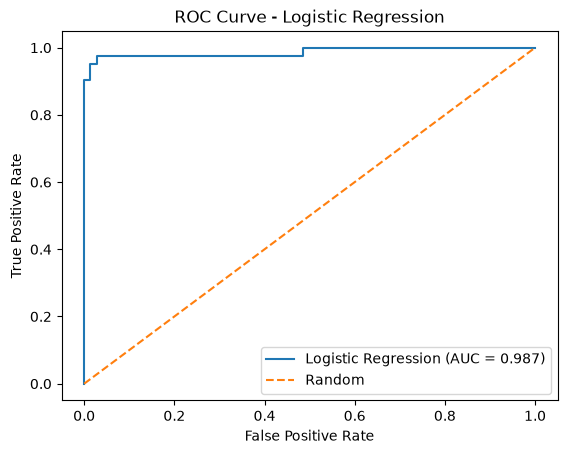

In [65]:
y_prob = final_model.predict_proba(X_test_sc)[:, 1]

auc = roc_auc_score(Y_test, y_prob)

print("ROC-AUC:", auc)
print(y_prob[:10])
print(len(set(y_prob)))
fpr, tpr, thresholds = roc_curve(Y_test, y_prob)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

An auc of 0.987 ~ 1 says that the model has perfect discrimintion.

In [67]:
coefficients = final_model.coef_[0]
print(coefficients)

[ 0.58965753  0.38866048  0.56452136  0.59520747  0.12028654 -0.18975233
  0.87993614  0.84542497  0.08869502 -0.44861879  1.11278692 -0.30199141
  0.58571041  0.88292874  0.37821413 -0.7733524   0.06758914  0.19058361
 -0.44101914 -0.75166496  0.96899155  1.51304324  0.76068618  0.8941162
  0.43284597 -0.0543643   0.81907121  0.90915066  0.94520173  0.49133412]


30 weights for 30 features.

In [68]:
feature_importance = pd.Series(
    coefficients,
    index=X_train.columns
).sort_values()

print(feature_importance)

compactness_se            -0.773352
fractal_dimension_se      -0.751665
fractal_dimension_mean    -0.448619
symmetry_se               -0.441019
texture_se                -0.301991
compactness_mean          -0.189752
compactness_worst         -0.054364
concavity_se               0.067589
symmetry_mean              0.088695
smoothness_mean            0.120287
concave points_se          0.190584
smoothness_se              0.378214
texture_mean               0.388660
smoothness_worst           0.432846
fractal_dimension_worst    0.491334
perimeter_mean             0.564521
perimeter_se               0.585710
radius_mean                0.589658
area_mean                  0.595207
perimeter_worst            0.760686
concavity_worst            0.819071
concave points_mean        0.845425
concavity_mean             0.879936
area_se                    0.882929
area_worst                 0.894116
concave points_worst       0.909151
symmetry_worst             0.945202
radius_worst               0

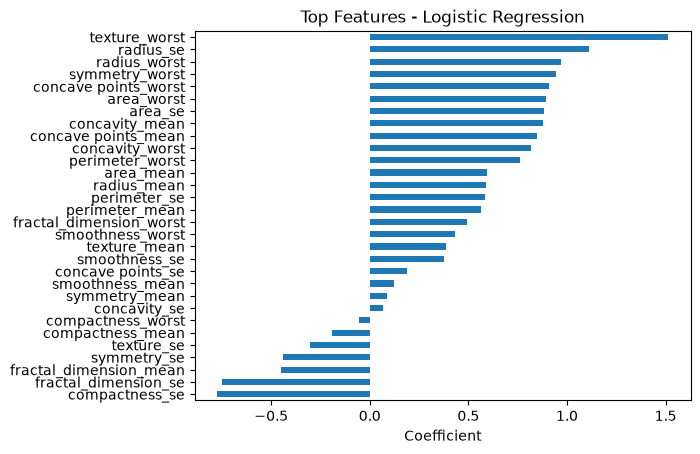

In [70]:
feature_importance.tail(30).plot(kind="barh")
plt.title("Top Features - Logistic Regression")
plt.xlabel("Coefficient")
plt.show()

The positive features push towards a case being Malign and else negative ones push towards benign.